In [1]:
import torch, time, csv, cv2, numpy as np
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

ROOT = Path("/home/xuand/vn_traffic_ai")
DATA = ROOT / "data/merged_v6"

IMG_TR, LBL_TR = DATA / "images/train", DATA / "labels/train"
IMG_VA, LBL_VA = DATA / "images/val",   DATA / "labels/val"
IMG_TE, LBL_TE = DATA / "images/test",  DATA / "labels/test"

CLASSES = ["motorcycle", "car", "bus", "truck"]   # index 0..3 trong label (background = class 0 trong FRCNN)
NC = len(CLASSES)

# ────── Config đã tối ưu ──────
EPOCHS        = 30
BATCH         = 4              # Faster R-CNN với FPN rất tốn VRAM → batch nhỏ hơn YOLO
IMGSZ_MIN     = 800            # Faster R-CNN FPN gốc train ở 800/1333 → giữ nguyên để không phá feature
IMGSZ_MAX     = 1333
LR            = 0.005          # Linear scaling rule: lr=0.02 * batch/16 = 0.005 cho batch=4
WARMUP_EPOCHS = 2              # Warmup linear 2 epoch rồi cosine
GRAD_CLIP     = 10.0           # Faster R-CNN dễ explode gradient → clip
EVAL_EVERY    = 2              # Val mAP mỗi 2 epoch (tiết kiệm thời gian)
ACCUM_STEPS   = 2              # Gradient accumulation → effective batch = 4*2 = 8

CKPT_DIR = ROOT/"weights/trained/frcnn"; CKPT_DIR.mkdir(parents=True, exist_ok=True)
LOG_CSV  = ROOT/"logs/frcnn_train.csv"
LOG_CSV.parent.mkdir(parents=True, exist_ok=True)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {dev} | Batch: {BATCH} (effective {BATCH*ACCUM_STEPS}) | LR: {LR} | Imgsz: {IMGSZ_MIN}-{IMGSZ_MAX}")

Device: cuda | Batch: 4 (effective 8) | LR: 0.005 | Imgsz: 800-1333


In [2]:
class YoloDet(Dataset):
    """Dataset YOLO format -> trả (image_tensor, {boxes, labels}) cho Faster R-CNN.

    Tối ưu:
    - SKIP ảnh không có label hoặc 0 box (FRCNN train với empty target -> NaN loss)
    - Augmentation nhẹ cho train: flip + color jitter + random brightness
    - Label shift: YOLO class 0 -> FRCNN class 1 (vì FRCNN reserve 0 cho background)
    """
    def __init__(self, img_dir, lbl_dir, train=False):
        self.lbl_dir, self.train = Path(lbl_dir), train
        # Chỉ giữ ảnh CÓ label và label không rỗng
        self.imgs = []
        for p in sorted(Path(img_dir).glob("*.jpg")) + sorted(Path(img_dir).glob("*.png")):
            lbl = self.lbl_dir / f"{p.stem}.txt"
            if lbl.exists() and lbl.stat().st_size > 0:
                self.imgs.append(p)
        print(f"  {img_dir.name}: {len(self.imgs)} ảnh có label hợp lệ")

    def __len__(self): return len(self.imgs)

    def _augment(self, img):
        """Color jitter + brightness nhẹ (chỉ train)."""
        if torch.rand(1) < 0.5:   # brightness/contrast
            alpha = 0.8 + 0.4 * torch.rand(1).item()   # 0.8-1.2
            beta = int(-20 + 40 * torch.rand(1).item())  # -20..+20
            img = np.clip(img.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)
        if torch.rand(1) < 0.3:   # hue shift
            hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.int32)
            hsv[..., 0] = (hsv[..., 0] + int(-10 + 20 * torch.rand(1).item())) % 180
            img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
        return img

    def __getitem__(self, i):
        p = self.imgs[i]
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        # Parse label YOLO format
        boxes, labels = [], []
        for line in (self.lbl_dir / f"{p.stem}.txt").read_text().splitlines():
            if not line.strip(): continue
            c, cx, cy, bw, bh = map(float, line.split()[:5])
            boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
            labels.append(int(c) + 1)   # +1 vì FRCNN class 0 = background

        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor(labels, dtype=torch.int64)

        # Augmentation cho train
        if self.train:
            img = self._augment(img)
            if torch.rand(1) < 0.5:   # horizontal flip
                img = img[:, ::-1].copy()
                boxes[:, [0, 2]] = w - boxes[:, [2, 0]]

        # Clip boxes về trong ảnh (phòng augmentation gây lệch)
        boxes[:, [0, 2]] = boxes[:, [0, 2]].clamp(0, w - 1)
        boxes[:, [1, 3]] = boxes[:, [1, 3]].clamp(0, h - 1)
        # Loại box có width hoặc height <= 1px (invalid cho FRCNN)
        keep = (boxes[:, 2] - boxes[:, 0] > 1) & (boxes[:, 3] - boxes[:, 1] > 1)
        boxes, labels = boxes[keep], labels[keep]

        x = torch.from_numpy(img).permute(2, 0, 1).float() / 255
        return x, {"boxes": boxes, "labels": labels}


def collate(b):
    """Loại sample có 0 box sau augmentation (edge case)."""
    valid = [(x, t) for x, t in b if len(t["boxes"]) > 0]
    if not valid:
        return collate(b)   # retry (hiếm)
    return tuple(zip(*valid))


print("=== Load datasets ===")
ds_tr = YoloDet(IMG_TR, LBL_TR, train=True)
ds_va = YoloDet(IMG_VA, LBL_VA, train=False)
ds_te = YoloDet(IMG_TE, LBL_TE, train=False)

dl_tr = DataLoader(ds_tr, BATCH, shuffle=True,  num_workers=4, collate_fn=collate, pin_memory=True, drop_last=True)
dl_va = DataLoader(ds_va, BATCH, shuffle=False, num_workers=4, collate_fn=collate, pin_memory=True)
dl_te = DataLoader(ds_te, BATCH, shuffle=False, num_workers=4, collate_fn=collate, pin_memory=True)
print(f"Batches: train={len(dl_tr)} val={len(dl_va)} test={len(dl_te)}")

=== Load datasets ===
  train: 7229 ảnh có label hợp lệ
  val: 1460 ảnh có label hợp lệ
  test: 1499 ảnh có label hợp lệ
Batches: train=1807 val=365 test=375


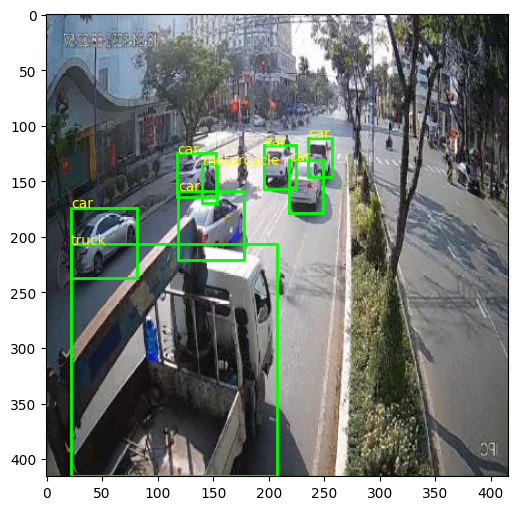

In [3]:
import matplotlib.pyplot as plt, matplotlib.patches as pa
x, t = dl_tr.dataset[0]
fig, ax = plt.subplots(figsize=(10,6)); ax.imshow(x.permute(1,2,0))
for b, l in zip(t["boxes"], t["labels"]):
    ax.add_patch(pa.Rectangle((b[0],b[1]), b[2]-b[0], b[3]-b[1], fill=False, color="lime", lw=2))
    ax.text(b[0], b[1], CLASSES[l-1], color="yellow")
plt.show()

In [4]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

def build(nc=NC, freeze_backbone=False):
    """Build Faster R-CNN với config tối ưu.

    - min_size/max_size: giữ 800/1333 (default torchvision) để không phá FPN pretrain
    - box_score_thresh=0.05: nhanh hơn khi train (filter noise sớm)
    - freeze_backbone: freeze resnet50 nếu True (tiết kiệm VRAM + ổn định đầu train)
    """
    m = fasterrcnn_resnet50_fpn(
        weights="DEFAULT",
        min_size=IMGSZ_MIN,          # 800 — standard FPN
        max_size=IMGSZ_MAX,          # 1333
        box_score_thresh=0.05,       # thresh cho train/val (sẽ override khi test)
        box_detections_per_img=100,
        box_nms_thresh=0.5,
        rpn_pre_nms_top_n_train=2000,   # default — đủ cho VN traffic
        rpn_post_nms_top_n_train=1000,
    )

    # Thay classifier head cho 4 class VN
    inf = m.roi_heads.box_predictor.cls_score.in_features
    m.roi_heads.box_predictor = FastRCNNPredictor(inf, nc + 1)  # +1 background

    if freeze_backbone:
        for p in m.backbone.body.parameters():
            p.requires_grad = False
        print("  [freeze] backbone ResNet50 frozen — chỉ train FPN + RPN + Head")

    return m


model = build(freeze_backbone=False).to(dev)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
print(f"Model: {n_params:.1f}M params ({n_trainable:.1f}M trainable)")

Model: 41.3M params (41.1M trainable)


In [5]:
from torchmetrics.detection import MeanAveragePrecision

# ────── Optimizer: 2 nhóm param, weight_decay chuẩn ──────
# Faster R-CNN best practice: no wd cho norm layers + bias
decay, no_decay = [], []
for name, p in model.named_parameters():
    if not p.requires_grad: continue
    if p.ndim <= 1 or name.endswith(".bias"):   # bias + norm
        no_decay.append(p)
    else:
        decay.append(p)
opt = torch.optim.SGD(
    [{"params": decay, "weight_decay": 5e-4},
     {"params": no_decay, "weight_decay": 0.0}],
    lr=LR, momentum=0.9, nesterov=True
)

# ────── Scheduler: Linear warmup -> Cosine ──────
total_steps  = len(dl_tr) * EPOCHS
warmup_steps = len(dl_tr) * WARMUP_EPOCHS

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps   # linear warmup
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + np.cos(np.pi * progress))   # cosine decay

sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
scaler = torch.amp.GradScaler()

# ────── Resume + Best tracking (defensive) ──────
last_pt = CKPT_DIR/"last.pt"
best_pt = CKPT_DIR/"best.pt"
start, best_map = 0, 0.0
if last_pt.exists():
    try:
        ck = torch.load(last_pt, map_location=dev, weights_only=False)
        model.load_state_dict(ck["model"])
        # Chỉ resume opt/sched nếu config tương thích
        try:
            opt.load_state_dict(ck["opt"])
            sched.load_state_dict(ck["sched"])
            start = ck["epoch"] + 1
            best_map = ck.get("best_map", 0.0)
            print(f"[resume] FULL từ epoch {start}, best_map={best_map:.4f}")
        except (ValueError, KeyError) as e:
            print(f"[resume] SKIP opt/sched (config đổi): {e}")
            print(f"[resume] chỉ load MODEL weights, train lại từ epoch 0")
            start, best_map = 0, 0.0
    except Exception as e:
        print(f"[resume] LỖI load checkpoint: {e} → train from scratch")
        start, best_map = 0, 0.0

# ────── Val mAP (gọi mỗi EVAL_EVERY epoch) ──────
@torch.no_grad()
def eval_map(loader, max_batches=None):
    model.eval()
    metric = MeanAveragePrecision(iou_type="bbox")
    for i, (xs, ts) in enumerate(loader):
        if max_batches and i >= max_batches: break
        xs = [x.to(dev) for x in xs]
        preds = model(xs)
        preds_cpu = [{"boxes": o["boxes"].cpu(), "scores": o["scores"].cpu(),
                      "labels": o["labels"].cpu()} for o in preds]
        targets  = [{"boxes": t["boxes"], "labels": t["labels"]} for t in ts]
        metric.update(preds_cpu, targets)
    return metric.compute()

# Init log CSV nếu chưa có
if not LOG_CSV.exists():
    with open(LOG_CSV, "w", newline="") as f:
        csv.writer(f).writerow(["epoch", "train_loss", "val_mAP50", "val_mAP", "lr"])

# ────── Train loop ──────
for ep in range(start, EPOCHS):
    model.train()
    ep_loss, n_batches = 0.0, 0
    t0 = time.time()
    opt.zero_grad(set_to_none=True)

    for i, (xs, ts) in enumerate(dl_tr):
        xs = [x.to(dev, non_blocking=True) for x in xs]
        ts = [{k: v.to(dev, non_blocking=True) for k, v in t.items()} for t in ts]

        with torch.autocast("cuda"):
            loss_dict = model(xs, ts)
            loss = sum(loss_dict.values()) / ACCUM_STEPS   # chia cho accumulation

        scaler.scale(loss).backward()

        if (i + 1) % ACCUM_STEPS == 0:
            # Gradient clipping (Faster R-CNN thường bị explode)
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(opt)
            scaler.update()
            opt.zero_grad(set_to_none=True)
            sched.step()

        ep_loss += loss.item() * ACCUM_STEPS   # recover scale cho log
        n_batches += 1

        if i % 50 == 0:
            cur_lr = opt.param_groups[0]["lr"]
            print(f"  ep{ep} [{i+1}/{len(dl_tr)}] loss={loss.item()*ACCUM_STEPS:.3f} lr={cur_lr:.5f}")

    avg_loss = ep_loss / n_batches

    # ────── Validation ──────
    val_map50 = val_map = float("nan")
    if (ep + 1) % EVAL_EVERY == 0 or ep == EPOCHS - 1:
        print(f"  Evaluating epoch {ep}...")
        metrics = eval_map(dl_va, max_batches=50)   # 50 batch = 200 ảnh val đủ cho signal
        val_map50 = float(metrics["map_50"])
        val_map   = float(metrics["map"])

        # Save best
        if val_map50 > best_map:
            best_map = val_map50
            torch.save({"model": model.state_dict(), "epoch": ep,
                        "val_map50": val_map50, "val_map": val_map},
                       best_pt)
            print(f"  ⭐ NEW BEST mAP50={val_map50:.4f} → saved {best_pt.name}")

    # Save last checkpoint (resume được)
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(),
                "sched": sched.state_dict(), "epoch": ep,
                "best_map": best_map}, last_pt)

    # Log CSV
    cur_lr = opt.param_groups[0]["lr"]
    with open(LOG_CSV, "a", newline="") as f:
        csv.writer(f).writerow([ep, avg_loss, val_map50, val_map, cur_lr])

    dt = time.time() - t0
    print(f"EP {ep:2d}/{EPOCHS} | loss={avg_loss:.4f} | val_mAP50={val_map50:.4f} | "
          f"lr={cur_lr:.5f} | {dt:.1f}s")

print(f"\n✅ Train xong. Best mAP50 = {best_map:.4f}")
print(f"   Best: {best_pt}")
print(f"   Last: {last_pt}")

[resume] FULL từ epoch 5, best_map=0.9347
  ep5 [1/1807] loss=0.261 lr=0.00500
  ep5 [51/1807] loss=0.243 lr=0.00500
  ep5 [101/1807] loss=0.259 lr=0.00500
  ep5 [151/1807] loss=0.426 lr=0.00500
  ep5 [201/1807] loss=0.333 lr=0.00500
  ep5 [251/1807] loss=0.428 lr=0.00499
  ep5 [301/1807] loss=0.266 lr=0.00499
  ep5 [351/1807] loss=0.297 lr=0.00499
  ep5 [401/1807] loss=0.222 lr=0.00499
  ep5 [451/1807] loss=0.158 lr=0.00499
  ep5 [501/1807] loss=0.252 lr=0.00499
  ep5 [551/1807] loss=0.311 lr=0.00499
  ep5 [601/1807] loss=0.262 lr=0.00499
  ep5 [651/1807] loss=0.379 lr=0.00499
  ep5 [701/1807] loss=0.318 lr=0.00499
  ep5 [751/1807] loss=0.210 lr=0.00499
  ep5 [801/1807] loss=0.251 lr=0.00499
  ep5 [851/1807] loss=0.225 lr=0.00499
  ep5 [901/1807] loss=0.362 lr=0.00499
  ep5 [951/1807] loss=0.292 lr=0.00499
  ep5 [1001/1807] loss=0.343 lr=0.00499
  ep5 [1051/1807] loss=0.304 lr=0.00499
  ep5 [1101/1807] loss=0.281 lr=0.00499
  ep5 [1151/1807] loss=0.257 lr=0.00499
  ep5 [1201/1807] los

In [6]:
from torchmetrics.detection import MeanAveragePrecision

def evaluate(predict_fn, loader):
    """predict_fn(list_of_tensors) -> list of dict(boxes, scores, labels) với labels 0..NC-1"""
    m = MeanAveragePrecision(iou_type="bbox", class_metrics=True)
    for xs, ts in loader:
        preds = predict_fn(xs)
        tgts = [{"boxes": t["boxes"], "labels": t["labels"] - 1} for t in ts]   # về 0..3
        m.update(preds, tgts)
    return m.compute()

@torch.no_grad()
def frcnn_predict(xs):
    model.eval()
    out = model([x.to(dev) for x in xs])
    return [{"boxes": o["boxes"].cpu(), "scores": o["scores"].cpu(), "labels": o["labels"].cpu() - 1} for o in out]

r_f = evaluate(frcnn_predict, dl_te)
print("FRCNN mAP50", r_f["map_50"].item(), "mAP50-95", r_f["map"].item(), r_f["map_per_class"])

FRCNN mAP50 0.5140828490257263 mAP50-95 0.29123201966285706 tensor([0.1924, 0.4157, 0.3221, 0.2348])


In [ ]:
from ultralytics import YOLO
YOLO_CKPT = ROOT/"runs/detect/train_v8s_v6_pseudo/weights/best.pt"   # v8s train trên data_v6.yaml, imgsz=960
YOLO_IMGSZ = 960                                                     # match train imgsz

yolo = YOLO(YOLO_CKPT)

def yolo_predict(xs):
    imgs = [(x.permute(1,2,0).numpy()*255).astype(np.uint8)[:, :, ::-1] for x in xs]   # RGB -> BGR
    res = yolo.predict(imgs, imgsz=YOLO_IMGSZ, conf=0.001, iou=0.6, verbose=False)
    return [{"boxes": r.boxes.xyxy.cpu(), "scores": r.boxes.conf.cpu(),
             "labels": r.boxes.cls.cpu().long()} for r in res]

r_y = evaluate(yolo_predict, dl_te)
print("YOLOv8s mAP50", r_y["map_50"].item(), "mAP50-95", r_y["map"].item(), r_y["map_per_class"])

In [ ]:
# ─────────────────────────────────────────────────────────────
# YOLOv8s GỐC (pretrained COCO, chưa fine-tune)
# COCO 80 class → map 4 class VN:
#   COCO 3 (motorcycle) → VN 0 (motorcycle)
#   COCO 2 (car)        → VN 1 (car)
#   COCO 5 (bus)        → VN 2 (bus)
#   COCO 7 (truck)      → VN 3 (truck)
# Các class khác → bỏ (không count)
# ─────────────────────────────────────────────────────────────
YOLO_COCO_CKPT  = ROOT/"yolov8s.pt"      # pretrained COCO, chưa train
YOLO_COCO_IMGSZ = 640

yolo_coco = YOLO(YOLO_COCO_CKPT)

# COCO id → VN id
COCO2VN = {3: 0, 2: 1, 5: 2, 7: 3}
KEEP_COCO = torch.tensor(list(COCO2VN.keys()))   # [3,2,5,7]

def yolo_coco_predict(xs):
    imgs = [(x.permute(1,2,0).numpy()*255).astype(np.uint8)[:, :, ::-1] for x in xs]
    res = yolo_coco.predict(imgs, imgsz=YOLO_COCO_IMGSZ, conf=0.001, iou=0.6, verbose=False)
    out = []
    for r in res:
        boxes  = r.boxes.xyxy.cpu()
        scores = r.boxes.conf.cpu()
        labels = r.boxes.cls.cpu().long()
        # Lọc chỉ giữ 4 class COCO quan tâm
        mask = torch.isin(labels, KEEP_COCO)
        boxes, scores, labels = boxes[mask], scores[mask], labels[mask]
        # Remap COCO id → VN id
        remapped = torch.tensor([COCO2VN[int(l)] for l in labels], dtype=torch.long) \
                   if len(labels) else torch.zeros(0, dtype=torch.long)
        out.append({"boxes": boxes, "scores": scores, "labels": remapped})
    return out

r_y0 = evaluate(yolo_coco_predict, dl_te)
print("YOLOv8s-COCO (zero-shot) mAP50", r_y0["map_50"].item(),
      "mAP50-95", r_y0["map"].item(), r_y0["map_per_class"])

In [ ]:
# ─────────────────────────────────────────────────────────────
# So sánh trực quan 3 model trên test set V6:
#   - YOLOv8s-COCO   (pretrained COCO, ZERO-SHOT, chưa fine-tune)
#   - YOLOv8s-V6     (fine-tune trên V6 pseudo)
#   - FRCNN-V6       (Faster R-CNN train trên V6)
# ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as pa
import numpy as np
import pandas as pd

def to_list(x):
    return x.cpu().numpy().tolist() if hasattr(x, "cpu") else list(x)

MODELS = {
    "YOLOv8s-COCO":{"res": r_y0, "predict": yolo_coco_predict, "color": "#9B59B6"},
    "YOLOv8s-V6":  {"res": r_y,  "predict": yolo_predict,      "color": "#E94B3C"},
    "FRCNN-V6":    {"res": r_f,  "predict": frcnn_predict,     "color": "#4A90E2"},
}
names = list(MODELS.keys())
per_class = {n: to_list(MODELS[n]["res"]["map_per_class"]) for n in names}

# ── 1. Bảng ──
rows = [["mAP@50"]    + [MODELS[n]["res"]["map_50"].item() for n in names],
        ["mAP@50-95"] + [MODELS[n]["res"]["map"].item()    for n in names]]
for i, c in enumerate(CLASSES):
    rows.append([f"mAP@50-95 ({c})"] + [per_class[n][i] for n in names])

df = pd.DataFrame(rows, columns=["Metric"] + names)
best_col = df[names].idxmax(axis=1)
df_disp = df.copy()
for col in names:
    df_disp[col] = [f"{v:.4f}" + (" ★" if best_col.iloc[i] == col else "")
                     for i, v in enumerate(df[col])]
print(df_disp.to_string(index=False))
print()

# ── 2. Bar chart ──
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
w = 0.25
offsets = np.linspace(-w, w, len(names))

ax = axes[0]
metrics = ["mAP@50", "mAP@50-95"]
x = np.arange(len(metrics))
for off, n in zip(offsets, names):
    vals = [MODELS[n]["res"]["map_50"].item(), MODELS[n]["res"]["map"].item()]
    bars = ax.bar(x + off, vals, w, label=n, color=MODELS[n]["color"])
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
                f"{b.get_height():.3f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylabel("mAP"); ax.set_title("Overall mAP — Test V6")
ax.legend(); ax.grid(axis="y", alpha=0.3)

ax = axes[1]
x = np.arange(len(CLASSES))
for off, n in zip(offsets, names):
    bars = ax.bar(x + off, per_class[n], w, label=n, color=MODELS[n]["color"])
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
                f"{b.get_height():.3f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(CLASSES)
ax.set_ylabel("mAP@50-95"); ax.set_title("Per-class mAP@50-95")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

# ── 3. Qualitative: 3 ảnh × 4 cột ──
N_SAMPLES = 3
CONF_VIZ  = 0.3
sample_idxs = np.random.RandomState(42).choice(len(ds_te), N_SAMPLES, replace=False)

ncols = 1 + len(names)
fig, axes = plt.subplots(N_SAMPLES, ncols, figsize=(5 * ncols, 5 * N_SAMPLES))
if N_SAMPLES == 1: axes = axes[None, :]

def draw(ax, img, boxes, labels, scores=None, title=""):
    ax.imshow(img); ax.set_title(title, fontsize=11); ax.axis("off")
    colors = ["#FFD700", "#00FF7F", "#FF69B4", "#00BFFF"]
    for i, (b, l) in enumerate(zip(boxes, labels)):
        l_idx = int(l); c = colors[l_idx % len(colors)]
        ax.add_patch(pa.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                   fill=False, edgecolor=c, lw=2))
        txt = CLASSES[l_idx] if 0 <= l_idx < len(CLASSES) else str(l_idx)
        if scores is not None:
            txt += f" {float(scores[i]):.2f}"
        ax.text(b[0], max(b[1]-3, 0), txt, color="black", fontsize=8,
                bbox=dict(facecolor=c, alpha=0.8, pad=1, edgecolor="none"))

for row, idx in enumerate(sample_idxs):
    x, t = ds_te[idx]
    img = x.permute(1, 2, 0).numpy()
    draw(axes[row, 0], img, t["boxes"], t["labels"] - 1,
         title=f"GT — {ds_te.imgs[idx].name}")
    for col, n in enumerate(names, start=1):
        p = MODELS[n]["predict"]([x])[0]
        keep = p["scores"] >= CONF_VIZ
        draw(axes[row, col], img, p["boxes"][keep], p["labels"][keep],
             p["scores"][keep], title=f"{n} (conf≥{CONF_VIZ})")

plt.tight_layout(); plt.show()

# ── 4. Winner per-class ──
print("\n=== Per-class winner (mAP@50-95) ===")
for i, c in enumerate(CLASSES):
    vals = {n: per_class[n][i] for n in names}
    winner = max(vals, key=vals.get)
    vals_str = "  ".join(f"{n}={v:.4f}" for n, v in vals.items())
    print(f"  {c:12s}: {vals_str}   →  {winner}")

# ── 5. Ablation: fine-tune domain VN có giúp không? ──
print("\n=== Ablation: fine-tune trên data VN có giúp YOLO không? ===")
d50_y = r_y["map_50"].item()  - r_y0["map_50"].item()
d_y   = r_y["map"].item()     - r_y0["map"].item()
print(f"  YOLO V6 vs COCO:  Δ mAP@50 = {d50_y:+.4f}   Δ mAP@50-95 = {d_y:+.4f}")
print(f"  → {'Fine-tune CẢI THIỆN YOLO' if d_y > 0 else 'Fine-tune KHÔNG cải thiện YOLO'}")

print("\n=== So kiến trúc: FRCNN vs YOLOv8s (cùng V6) ===")
d50_a = r_f["map_50"].item()  - r_y["map_50"].item()
d_a   = r_f["map"].item()     - r_y["map"].item()
print(f"  FRCNN vs YOLO:   Δ mAP@50 = {d50_a:+.4f}   Δ mAP@50-95 = {d_a:+.4f}")
print(f"  → {'FRCNN thắng' if d_a > 0 else 'YOLO thắng'}")